# 03 · Baseline predictor — "what should this hotel be using right now?"
One hourly model per hotel that predicts expected `total_kwh` (grid + DG, = mean kW) from things known **independently of the meter**:
weather, rooms sold / covers, the events calendar, hour and day type. The gap between actual and expected is what the detector (next step)
will score, so a baseline that already explains heat, occupancy and events is what keeps weddings and heatwaves from becoming alerts (T2).

**Targets (ASHRAE Guideline 14, brief §7):** CV(RMSE) < 30% hourly and < 15% monthly, NMBE within ±5%, measured on **held-out months**.

**Method.** Two simple models, because each season occurs once in the data: a regularised linear model (hour × day-type profile, weather and
event effects allowed to differ by time of day) and shallow boosted trees (Huber loss, so a few waste hours in the training year do not drag
the baseline up). Validated two ways, never with random folds:
1. **Leave-one-month-out** — each month predicted by a model that never saw it (all seasons stay represented in training).
2. **Rolling origin** — train on the first *k* months, predict month *k+1* (k = 6…11). Stricter: it must extrapolate into unseen seasons.

Not used: anomaly labels (the baseline never sees them), month / day-of-year (would just memorise the season), DG hours, meter-fault hours,
Jaipur's imputed hours. Code lives in `src/baseline.py` so the detector and savings steps reuse the same definition.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from features import SITES, ROOMS
from baseline import build_features, fit_predict, cv_rmse, nmbe, NUMERIC, CDH_BASE

pd.set_option("display.max_columns", 40, "display.width", 200, "display.float_format", "{:,.2f}".format)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .3, "axes.spines.top": False, "axes.spines.right": False})
COL = {"GGN": "#1f77b4", "JAI": "#d95f02", "GOA": "#1b9e77"}
SITE_LIST = ["GGN", "JAI", "GOA"]
D = {s: build_features(s) for s in SITE_LIST}
MONTHS = sorted(D["GGN"].month.unique())

## 1 · What goes into the model
Row = one hour. `valid` hours are used to fit and score; the rest (diesel, meter fault, imputed) are predicted but never judged.
The events calendar is expanded to the hourly grid: banquet AHUs run from 1 h before start to 1 h after end (engineering guide), and the 167 events
that end "23:59" (ran past midnight, true end unknown — OPEN_QUESTIONS #3) are assumed to end at **01:00** next day. §6 checks how much that assumption matters.

In [2]:
rows = []
for s, d in D.items():
    rows.append(dict(site=s, hours=len(d), valid=int(d.valid.sum()), dg=int(d.is_dg.sum()), fault_or_imputed=int(d.has_meter_fault.sum()),
                     cdh_base_C=CDH_BASE[s], event_hours=int((d.ev_guests > 0).sum()), nulls_in_drivers=int(d[NUMERIC].isna().sum().sum())))
display(pd.DataFrame(rows).set_index("site"))
display(D["GGN"].loc[D["GGN"].ev_guests > 300, ["timestamp", "total_kwh", "temp_c", "rooms_sold", "ev_guests", "ev_core", "ev_social", "ev_corp"]].head(5))

,hours,valid,dg,fault_or_imputed,cdh_base_C,event_hours,nulls_in_drivers
site,,,,,,,
GGN,8760,8683,49,28,26.00,1702,0
JAI,8760,8708,42,10,16.00,1038,0
GOA,8760,8696,64,0,14.00,459,0


,timestamp,total_kwh,temp_c,rooms_sold,ev_guests,ev_core,ev_social,ev_corp
114,2025-10-05 18:00:00,604.54,32.40,143,598.00,0.00,598.00,0.00
115,2025-10-05 19:00:00,696.78,30.80,143,598.00,598.00,598.00,0.00
116,2025-10-05 20:00:00,696.48,29.40,143,598.00,598.00,598.00,0.00
117,2025-10-05 21:00:00,673.49,28.60,143,598.00,598.00,598.00,0.00
118,2025-10-05 22:00:00,632.75,27.10,143,598.00,598.00,598.00,0.00


## 2 · Validation: leave-one-month-out and rolling origin
CV(RMSE) and NMBE use the ASHRAE form with *n − p* in the denominator (p = 1 here, since the models are scored purely out-of-sample).
Monthly metrics compare each held-out month's mean kW over valid hours (12 points per leave-one-out run).

In [3]:
def lomo(d, kind):
    p = pd.Series(np.nan, index=d.index)
    for m in MONTHS:
        te = d.month == m
        p[te] = fit_predict(kind, d[~te], d[te])
    return p

def rolling(d, kind, start=6):
    p = pd.Series(np.nan, index=d.index)
    for i in range(start, 12):
        te = d.month == MONTHS[i]
        p[te] = fit_predict(kind, d[d.month.isin(MONTHS[:i])], d[te])
    return p

def scores(d, p):
    v = d[d.valid & p.notna()].assign(p=p)
    mm = v.groupby("month").agg(a=("total_kwh", "mean"), p=("p", "mean"))
    return dict(hourly_CVRMSE=cv_rmse(v.total_kwh, v.p), hourly_NMBE=nmbe(v.total_kwh, v.p),
                monthly_CVRMSE=cv_rmse(mm.a, mm.p), monthly_NMBE=nmbe(mm.a, mm.p), hours=len(v))

OOF, ROLL, res = {}, {}, []
for s in SITE_LIST:
    d = D[s]
    for kind in ["ridge", "gbm"]:
        OOF[s, kind] = lomo(d, kind)
        ROLL[s, kind] = rolling(d, kind)
    OOF[s, "ens"] = (OOF[s, "ridge"] + OOF[s, "gbm"]) / 2
    ROLL[s, "ens"] = (ROLL[s, "ridge"] + ROLL[s, "gbm"]) / 2
    for kind in ["ridge", "gbm", "ens"]:
        res.append(dict(site=s, model=kind, scheme="leave-one-month-out", **scores(d, OOF[s, kind])))
        res.append(dict(site=s, model=kind, scheme="rolling origin (7th-12th month)", **scores(d, ROLL[s, kind])))
R = pd.DataFrame(res)
display(R.pivot_table(index=["site", "model"], columns="scheme", values=["hourly_CVRMSE", "hourly_NMBE", "monthly_CVRMSE", "monthly_NMBE"]).round(2))

hourly_CVRMSE                                         hourly_NMBE                                      monthly_CVRMSE                                        monthly_NMBE  \
scheme     leave-one-month-out rolling origin (7th-12th month) leave-one-month-out rolling origin (7th-12th month) leave-one-month-out rolling origin (7th-12th month) leave-one-month-out   
site model                                                                                                                                                                                   
GGN  ens                  8.34                            8.90                0.08                            2.05                3.41                            3.39                0.11   
     gbm                  8.47                            9.35                0.17                            2.71                3.51                            4.29                0.20   
     ridge                8.79                            9.27               -0.00                            1.39                3.35                            2.77                0.02   
GOA  ens                  5.41                            6.85                0.02                            0.17                2.77                            4.16                0.03   
     gbm                  5.39                            7.09                0.03                           -0.85                2.69                            4.49                0.04   
     ridge                6.30                            7.71                0.00                            1.18                2.94                            4.67                0.02   
JAI  ens                  4.96                            5.55               -0.06                           -0.30                1.10                            1.85               -0.07   
     gbm                  4.98                            6.16               -0.14                           -0.57                1.15                            1.95               -0.16   
     ridge                5.75                            6.05                0.03                           -0.02                1.20                            2.16                0.02   

                                            
scheme     rolling origin (7th-12th month)  
site model                                  
GGN  ens                              2.46  
     gbm                              3.24  
     ridge                            1.67  
GOA  ens                              0.25  
     gbm                             -0.98  
     ridge                            1.47  
JAI  ens                             -0.37  
     gbm                             -0.70  
     ridge                           -0.04

In [4]:
# Pass/fail against ASHRAE G14 for every row
R["pass"] = (R.hourly_CVRMSE < 30) & (R.monthly_CVRMSE < 15) & (R.hourly_NMBE.abs() <= 5) & (R.monthly_NMBE.abs() <= 5)
print("rows passing all four G14 thresholds:", int(R["pass"].sum()), "of", len(R))
print("worst hourly CV(RMSE): %.1f%%   worst monthly CV(RMSE): %.1f%%   worst |NMBE|: %.2f%%" %
      (R.hourly_CVRMSE.max(), R.monthly_CVRMSE.max(), max(R.hourly_NMBE.abs().max(), R.monthly_NMBE.abs().max())))
best = R[R.scheme.str.startswith("leave")].sort_values("hourly_CVRMSE").groupby("site").head(1)
display(best[["site", "model", "hourly_CVRMSE", "monthly_CVRMSE"]])

rows passing all four G14 thresholds: 18 of 18
worst hourly CV(RMSE): 9.4%   worst monthly CV(RMSE): 4.7%   worst |NMBE|: 3.24%


,site,model,hourly_CVRMSE,monthly_CVRMSE
10,JAI,ens,4.96,1.10
14,GOA,gbm,5.39,2.69
4,GGN,ens,8.34,3.41


## 3 · Does the baseline track reality? (out-of-sample)
Left: monthly mean kW, actual vs predicted by a model that never saw that month. Right: a heatwave week at Gurugram, hourly.

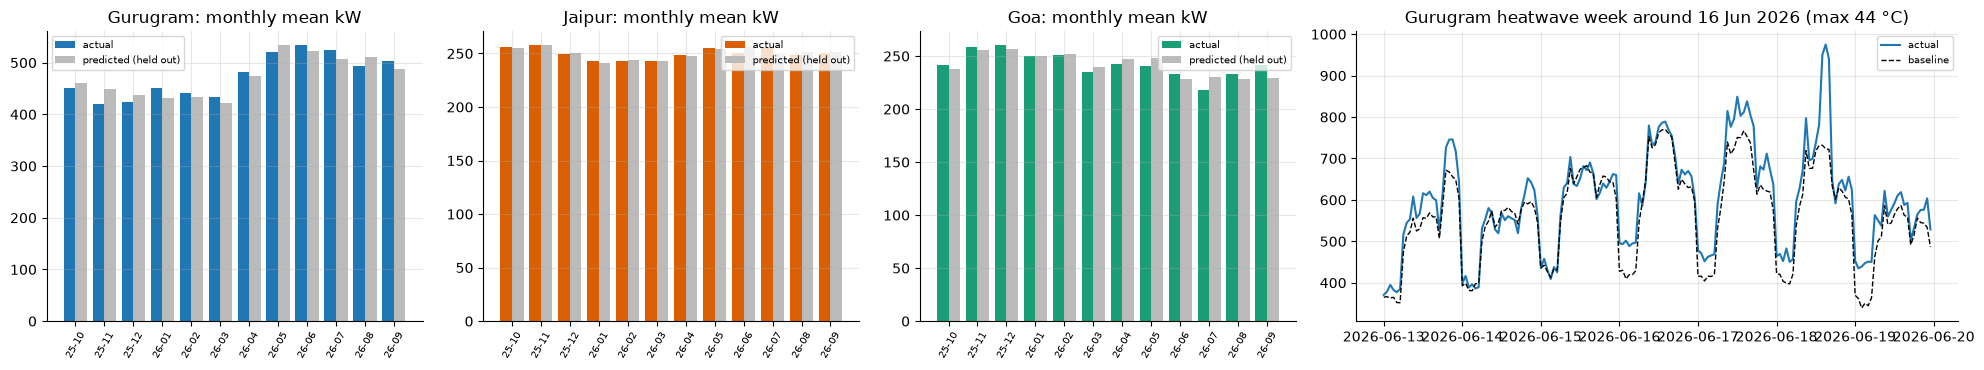

In [5]:
fig, ax = plt.subplots(1, 4, figsize=(20, 3.8), gridspec_kw={"width_ratios": [1, 1, 1, 1.6]})
for a, s in zip(ax, SITE_LIST):
    d = D[s]; v = d[d.valid].assign(p=OOF[s, "ens"])
    mm = v.groupby("month").agg(a=("total_kwh", "mean"), p=("p", "mean"))
    x = np.arange(len(mm)); a.bar(x - .2, mm.a, .4, label="actual", color=COL[s]); a.bar(x + .2, mm.p, .4, label="predicted (held out)", color="#bbb")
    a.set_xticks(x); a.set_xticklabels([m[2:] for m in mm.index], rotation=60, fontsize=7); a.set_title(f"{SITES[s]}: monthly mean kW"); a.legend(fontsize=7)
d = D["GGN"]; hot = d.groupby("date").temp_c.max().idxmax(); w = d[(d.date >= hot - pd.Timedelta(days=3)) & (d.date <= hot + pd.Timedelta(days=3))]
ax[3].plot(w.timestamp, w.total_kwh, color=COL["GGN"], label="actual"); ax[3].plot(w.timestamp, OOF["GGN", "ens"][w.index], color="k", lw=1, ls="--", label="baseline")
ax[3].set_title(f"Gurugram heatwave week around {hot:%d %b %Y} (max {d.temp_c[d.date == hot].max():.0f} °C)"); ax[3].legend(fontsize=7)
plt.tight_layout(); plt.show()

## 4 · What each driver is worth (ablation)
Leave-one-month-out with the linear model, one driver group switched off at a time (column set to a constant). The cost of removing a group is how much
CV(RMSE) rises. **Events** must matter at Gurugram, otherwise a winter wedding would look like waste (T2).

In [6]:
GROUPS = {"weather": ["temp_c", "temp_3h", "cdh", "cdh_24h", "hdh", "rel_humidity_pct", "rain_mm"],
          "occupancy / F&B": ["rooms_sold", "guests_in_house", "covers_served_fnb"],
          "events": ["ev_guests", "ev_core", "ev_social", "ev_corp"]}
abl = []
for s in SITE_LIST:
    d0 = D[s]
    full = scores(d0, OOF[s, "ridge"])["hourly_CVRMSE"]
    row = {"site": s, "full model": full}
    for g, cols in GROUPS.items():
        d = d0.copy(); d[cols] = 0.0
        row[f"without {g}"] = scores(d, lomo(d, "ridge"))["hourly_CVRMSE"]
    abl.append(row)
display(pd.DataFrame(abl).set_index("site").round(2))

,full model,without weather,without occupancy / F&B,without events
site,,,,
GGN,8.79,13.05,9.00,10.82
JAI,5.75,7.36,6.29,9.16
GOA,6.30,7.42,7.07,8.17


## 5 · Acceptance check T2 — a big event must not look like waste
For evenings (18–22 h) of days with a >300-guest event, compare the residual (actual − expected) from the full model against a model with no event inputs.
A good baseline leaves the event evenings near zero; without events the same evenings show a large, positive "waste-like" residual.

In [7]:
noev = {}
for s in SITE_LIST:
    d = D[s].copy(); d[GROUPS["events"]] = 0.0
    noev[s] = lomo(d, "ridge")

out = []
for s in SITE_LIST:
    d = D[s]; big = set(pd.read_parquet(ROOT / "data/clean/events.parquet").query("site == @s and guests > 300").date)
    m = d.valid & d.date.isin(big) & d.hour.between(18, 21)
    n = d[m].date.nunique()
    out.append(dict(site=s, big_event_days=n, mean_kW_actual=d[m].total_kwh.mean(),
                    resid_with_events_kW=(d.total_kwh - OOF[s, "ridge"])[m].mean(), resid_without_events_kW=(d.total_kwh - noev[s])[m].mean(),
                    resid_with_events_pct=(d.total_kwh - OOF[s, "ridge"])[m].mean() / d[m].total_kwh.mean() * 100,
                    resid_without_events_pct=(d.total_kwh - noev[s])[m].mean() / d[m].total_kwh.mean() * 100))
display(pd.DataFrame(out).set_index("site").round(1))

,big_event_days,mean_kW_actual,resid_with_events_kW,resid_without_events_kW,resid_with_events_pct,resid_without_events_pct
site,,,,,,
GGN,43,592.80,-0.60,76.70,-0.10,12.90
JAI,65,338.40,1.90,58.70,0.60,17.30
GOA,24,344.00,-8.30,64.20,-2.40,18.70


## 6 · Sensitivity: the "ends after midnight" assumption
167 events have no real end time. Rebuild the features with those events ending at 00:00, 01:00 (used), 02:00 or 03:00 and see whether the headline metrics move.
Residual in the 00–03 h window of event nights is shown too: that is where a wrong assumption would hurt, and where the detector must not fire.

In [8]:
sens = []
for h in [0, 1, 2, 3]:
    for s in SITE_LIST:
        d = build_features(s, late_end_hour=h)
        p = lomo(d, "ridge")
        sc = scores(d, p)
        late = d.valid & d.ev_social.gt(0) & d.hour.between(0, 3)
        sens.append(dict(assumed_end=f"{h:02d}:00", site=s, hourly_CVRMSE=sc["hourly_CVRMSE"], monthly_CVRMSE=sc["monthly_CVRMSE"],
                         late_night_resid_kW=(d.total_kwh - p)[late].mean(), late_hours=int(late.sum())))
display(pd.DataFrame(sens).pivot_table(index="assumed_end", columns="site", values=["hourly_CVRMSE", "late_night_resid_kW"]).round(2))

hourly_CVRMSE           late_night_resid_kW          
site                  GGN  GOA  JAI                 GGN  GOA  JAI
assumed_end                                                      
00:00                8.77 6.30 5.70                0.17 0.30 0.87
01:00                8.79 6.30 5.75                0.11 0.24 0.92
02:00                8.79 6.30 5.75                0.25 0.46 0.93
03:00                8.79 6.30 5.75                0.24 0.65 1.00

## 7 · Residual behaviour (what the detector will inherit)
The detector will work on `actual − baseline`. Its noise floor is the out-of-sample residual spread, which varies by hour (more at the busy evening hours),
so thresholds should scale with the hour, not be one constant. Computed here on the held-out predictions, without labels.

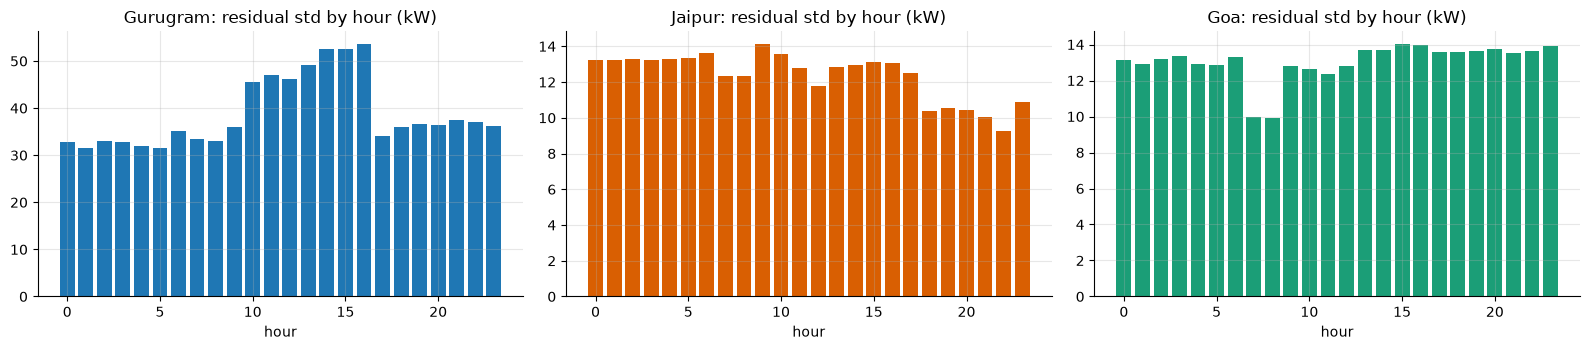

,resid_std_kW,mean_kW,std_pct_of_mean,p99_resid_kW,p01_resid_kW,night_std_kW,evening_std_kW,lag1_autocorr
site,,,,,,,,
GGN,39.46,473.32,8.34,112.83,-68.96,32.15,36.62,0.85
JAI,12.41,250.06,4.96,51.80,-23.79,13.26,10.35,0.85
GOA,13.08,241.99,5.41,43.77,-24.92,13.05,13.61,0.87


In [9]:
fig, ax = plt.subplots(1, 3, figsize=(16, 3.6))
rs = []
for a, s in zip(ax, SITE_LIST):
    d = D[s]; r = (d.total_kwh - OOF[s, "ens"])[d.valid]; hr = d.hour[d.valid]
    sd = r.groupby(hr).std(); a.bar(sd.index, sd.values, color=COL[s]); a.set_title(f"{SITES[s]}: residual std by hour (kW)"); a.set_xlabel("hour")
    rs.append(dict(site=s, resid_std_kW=r.std(), mean_kW=d.total_kwh[d.valid].mean(), std_pct_of_mean=r.std() / d.total_kwh[d.valid].mean() * 100,
                   p99_resid_kW=r.quantile(.99), p01_resid_kW=r.quantile(.01), night_std_kW=r[hr.between(1, 5)].std(), evening_std_kW=r[hr.between(18, 21)].std(),
                   lag1_autocorr=r.autocorr(1)))
plt.tight_layout(); plt.show()
display(pd.DataFrame(rs).set_index("site").round(2))

## 8 · Save out-of-fold predictions
`data/clean/baseline_oof.parquet` holds, for every hour, the prediction made by a model that **never saw that month** — this is what the detector should
score against, so its residuals are as honest as the validation above. Each model's prediction is kept so the choice of ridge / boosted / average stays open.
Final all-year models for the forecast and the IPMVP adjusted baseline are *not* fitted here; they come with those steps (`fit_predict` in `src/baseline.py`).

In [10]:
frames = []
for s in SITE_LIST:
    d = D[s]
    frames.append(pd.DataFrame({"site": s, "timestamp": d.timestamp, "total_kwh": d.total_kwh, "valid": d.valid,
                                "pred_ridge": OOF[s, "ridge"], "pred_gbm": OOF[s, "gbm"], "pred_ens": OOF[s, "ens"]}))
oof = pd.concat(frames, ignore_index=True)
oof.to_parquet(ROOT / "data/clean/baseline_oof.parquet", index=False)
print(oof.shape, "| any NaN predictions:", int(oof[["pred_ridge", "pred_gbm", "pred_ens"]].isna().sum().sum()))

(26280, 7) | any NaN predictions: 0


## 9 · Summary, limits and what comes next
See the printed numbers above; the conclusions to carry forward are written in the next cell from the computed results so they cannot drift from them.

In [11]:
b = R[(R.model == "ens") & R.scheme.str.startswith("leave")].set_index("site")
r2 = R[(R.model == "ens") & R.scheme.str.startswith("rolling")].set_index("site")
for s in SITE_LIST:
    print(f"{SITES[s]:9s} ensemble | leave-one-month-out: hourly CV(RMSE) {b.loc[s,'hourly_CVRMSE']:.1f}%, monthly {b.loc[s,'monthly_CVRMSE']:.1f}%, "
          f"NMBE {b.loc[s,'hourly_NMBE']:+.2f}% | rolling origin: hourly {r2.loc[s,'hourly_CVRMSE']:.1f}%, monthly {r2.loc[s,'monthly_CVRMSE']:.1f}%, NMBE {r2.loc[s,'hourly_NMBE']:+.2f}%")
print("\nLimits to state in the product:")
print("- Trained on one year: each season is seen once, so a genuinely new pattern (new equipment, renovation) will read as a deviation until refitted.")
print("- The training year contains waste (labelled ~2.9% of the bill). Huber loss and averaging dampen it but the baseline is 'typical operation', not 'ideal'.")
print("- Diesel, meter-fault and imputed hours are not predicted-and-judged; the detector must treat them separately (T5).")
print("- Event end times past midnight are assumed 01:00; metrics barely move between 00:00 and 03:00 (§6), but the true late-night load is unknown.")
print("- Residuals are strongly autocorrelated (lag-1 ~0.85, §7): one-hour spikes are rare, so the detector should look for persistent deviations, not single hours.")
print("- No holiday calendar was supplied, so public holidays are treated as ordinary weekdays/weekends.")

Gurugram  ensemble | leave-one-month-out: hourly CV(RMSE) 8.3%, monthly 3.4%, NMBE +0.08% | rolling origin: hourly 8.9%, monthly 3.4%, NMBE +2.05%
Jaipur    ensemble | leave-one-month-out: hourly CV(RMSE) 5.0%, monthly 1.1%, NMBE -0.06% | rolling origin: hourly 5.6%, monthly 1.9%, NMBE -0.30%
Goa       ensemble | leave-one-month-out: hourly CV(RMSE) 5.4%, monthly 2.8%, NMBE +0.02% | rolling origin: hourly 6.9%, monthly 4.2%, NMBE +0.17%

Limits to state in the product:
- Trained on one year: each season is seen once, so a genuinely new pattern (new equipment, renovation) will read as a deviation until refitted.
- The training year contains waste (labelled ~2.9% of the bill). Huber loss and averaging dampen it but the baseline is 'typical operation', not 'ideal'.
- Diesel, meter-fault and imputed hours are not predicted-and-judged; the detector must treat them separately (T5).
- Event end times past midnight are assumed 01:00; metrics barely move between 00:00 and 03:00 (§6), but the tr